In [1]:

import os
import re
import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

# Define paths for your files inside the data folder
file1 = os.path.join("data", "student_ai_tool_usage_dataset.csv")
file2 = os.path.join("data", "ai_student_impact_dataset (1).csv")
file3 = os.path.join("data", "ai_assistant_usage_student_life.csv")
file4 = os.path.join("data", "higher_education_students_performance.csv")


# 1. Primary Dataset 1
try:
    df_p1 = pd.read_csv(file1)
except FileNotFoundError:
    # Fallback if named without _dataset
    df_p1 = pd.read_csv(os.path.join("data", "student_ai_tool_usage.csv"))

print("=== PRIMARY DATASET 1: Student AI Tool Usage ===")
print("Shape:", df_p1.shape)
print("Data Types:\n", df_p1.dtypes)
print("\n" + "=" * 50 + "\n")

# 2. Primary Dataset 2
df_p2 = pd.read_csv(file2)
print("=== PRIMARY DATASET 2: AI Student Impact ===")
print("Shape:", df_p2.shape)
print("Data Types:\n", df_p2.dtypes)
print("\n" + "=" * 50 + "\n")

# 3. Secondary Dataset 1
df_s1 = pd.read_csv(file3)
print("=== SECONDARY DATASET 1: AI Assistant Usage ===")
print("Shape:", df_s1.shape)
print("Data Types:\n", df_s1.dtypes)

# 4. Secondary Dataset 2
df_s2 = pd.read_csv(file4)

print("=== SECONDARY DATASET 2: Higher Education Students Performance ===")
print("Shape:", df_s2.shape)
print("Data Types:\n", df_s2.dtypes)
print("\nFirst 5 rows:\n", df_s2.head())



=== PRIMARY DATASET 1: Student AI Tool Usage ===
Shape: (200, 8)
Data Types:
 timestamp               object
student_id              object
ai_tool_used            object
usage_hours_per_week    object
purpose                 object
satisfaction_level       int64
academic_performance    object
comments                object
dtype: object


=== PRIMARY DATASET 2: AI Student Impact ===
Shape: (50000, 16)
Data Types:
 Student_ID                      int64
Major_Category                 object
Year_of_Study                  object
Pre_Semester_GPA              float64
Weekly_GenAI_Hours            float64
Primary_Use_Case               object
Prompt_Engineering_Skill       object
Tool_Diversity                  int64
Paid_Subscription                bool
Traditional_Study_Hours       float64
Perceived_AI_Dependency         int64
Institutional_Policy           object
Anxiety_Level_During_Exams      int64
Post_Semester_GPA             float64
Skill_Retention_Score         float64
Burnout_Ris

In [2]:
# print(df_p1['usage_hours_per_week'].unique())
# ['2' '12' '1.5' '3' 'Everytime ' '4 or 6 hours ' '20 hours may be'
#  '2-3 hours' '5' '7 hours' '74' '10hrs' '21' '40-50' '15' '8 to 10'
#  'Unlimited ' '1 hour' '2 to 3 hours' '4,hours ' '25' '24 h' '3 Hours '
#  '3 to 4 hours' '14hr' '10' 'Limited in paper otherwise rare' '14' '9' '1'
#  '4' '13' '6' '11' '7' '8']

# this function is used to convert the values 
# in df_p1['usage_hours_per_week'] (object type) into real numbers 
def to_hours(x):
    s = str(x).strip().lower()

    # text answers with no usable number (plain text)
    text_words = ["everytime", "unlimited", "rare"]
    for word in text_words:
        if word in s:
            return np.nan

    # pull every number out of the text (such as '4 or 6 hours ' -> ["4", "6"])
    found = re.findall(r"\d+\.?\d*", s)

    nums = []
    for n in found:
        nums.append(float(n))

    # no numbers found -> nothing usable
    if len(nums) == 0:
        return np.nan

    # add the numbers up, then divide by how many there are.
    # one number returns itself; a range returns the average
    total = 0
    for n in nums:
        total += n

    return total / len(nums)


Q2. Anomalies: each anomaly is noted with what it is, how many rows it affects, and what was done about it.

Based on the analysis outcomes, there are some anomalies were indentified:
 - In Primary Dataset 1 (200 rows), both the timestamp and usage_hours_per_week columns are stored as generic object (string) data types
   which affects all 200 rows and prevents immediate time-series grouping or numerical calculations without type-casting
 - Secondary Dataset 2 (145 rows) features severe non-descriptive headers, where columns "1" through "30" are anonymized as raw numbers
   rather than explicit feature names, masking critical survey metrics across all rows 

Q3. Look at distributions. Make at least one plot of the distribution of each feature that matters to your research questions
(histogram, box plot, bar chart of counts, etc.), and describe its shape: center, spread, skew, outliers, etc.

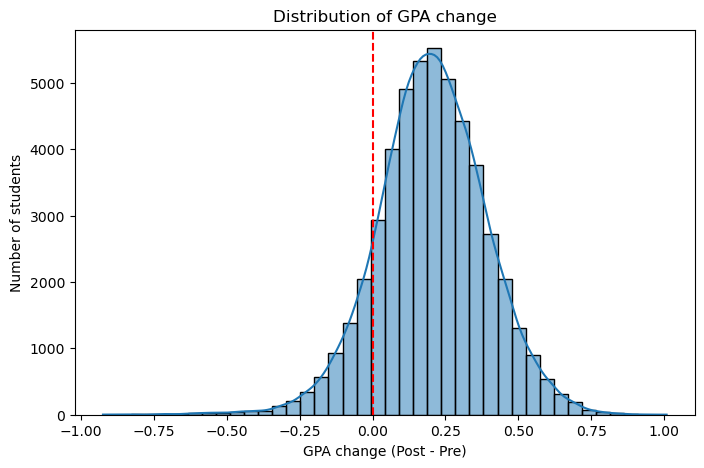

In [4]:
# GPA_Change (post-semester GPA minus pre-semester GPA) is the outcome variable in our primary research question, 
# so we need to understand its distribution before comparing it across levels of AI use. It is a continuous numeric variable, 
# so a histogram is the right choice because it shows the overall shape: where most students fall, 
# whether the changes are symmetric or skewed, and whether there are extreme values.

df_p2["GPA_Change"] = df_p2["Post_Semester_GPA"] - df_p2["Pre_Semester_GPA"]

plt.figure(figsize=(8, 5))
sns.histplot(df_p2["GPA_Change"], bins=40, kde=True)
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("GPA change (Post - Pre)")
plt.ylabel("Number of students")
plt.title("Distribution of GPA change")
plt.show()

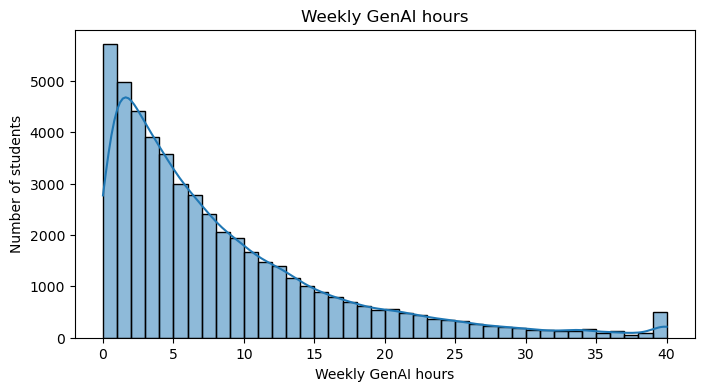

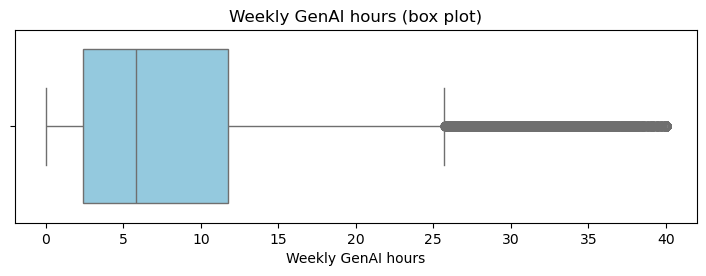

In [5]:
# Weekly_GenAI_Hours is the main predictor in our primary research question, so we need to understand its distribution 
# before relating it to GPA change. It is a continuous numeric variable, so a histogram is our choice to make a visualization 
# because it shows the overall shape: where most students fall, whether the data is skewed, and whether there are spikes or gaps. 
# Additionally, a box plot might also help because it summarizes the median, the middle 50% of students, 
# and the outliers in one compact view. Using both plots gives a complete picture of the predictor, 
# which tells us how to group students (such as low, medium, and high users) in the relationship plots that answer the research question.


# print(df_p2["Weekly_GenAI_Hours"].describe())

# histogram
plt.figure(figsize=(8, 4))
sns.histplot(df_p2["Weekly_GenAI_Hours"], bins=40, kde=True)
plt.xlabel("Weekly GenAI hours")
plt.ylabel("Number of students")
plt.title("Weekly GenAI hours")
plt.show()

# box plot
plt.figure(figsize=(8.8, 2.5))
sns.boxplot(x=df_p2["Weekly_GenAI_Hours"], color="skyblue")
plt.xlabel("Weekly GenAI hours")
plt.title("Weekly GenAI hours (box plot)")
plt.show()

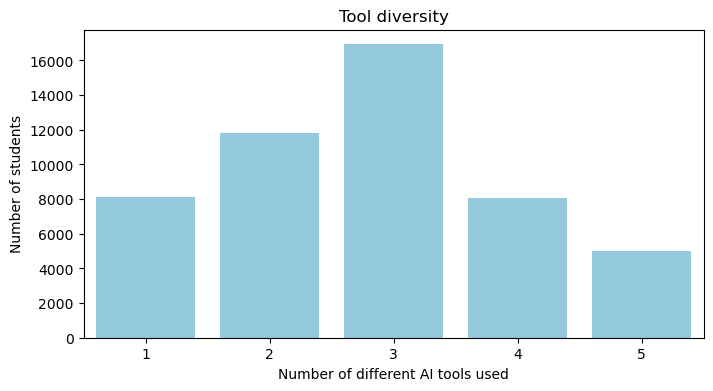

In [6]:
# print(df_p2["Tool_Diversity"].describe())

counts = df_p2["Tool_Diversity"].value_counts().sort_index().reset_index()
counts.columns = ["Tool_Diversity", "Students"]

plt.figure(figsize=(8, 4))
sns.barplot(data=counts, x="Tool_Diversity", y="Students", color="skyblue")
plt.xlabel("Number of different AI tools used")
plt.ylabel("Number of students")
plt.title("Tool diversity")
plt.show()

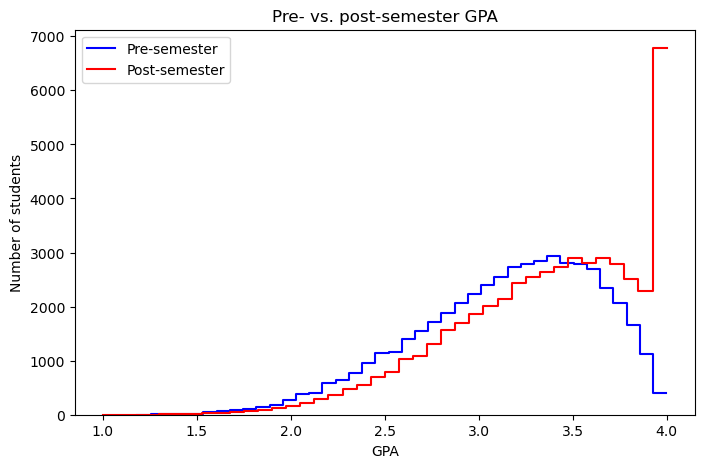

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(df_p2["Pre_Semester_GPA"], bins=40, element="step", fill=False, color="blue", label="Pre-semester")
sns.histplot(df_p2["Post_Semester_GPA"], bins=40, element="step", fill=False, color="red", label="Post-semester")

plt.xlabel("GPA")
plt.ylabel("Number of students")
plt.title("Pre- vs. post-semester GPA")
plt.legend()
plt.show()

                count   mean  median    std
Tool_Diversity                             
1                8141  0.182   0.186  0.179
2               11830  0.189   0.191  0.179
3               16926  0.207   0.207  0.190
4                8081  0.224   0.223  0.191
5                5022  0.225   0.223  0.197


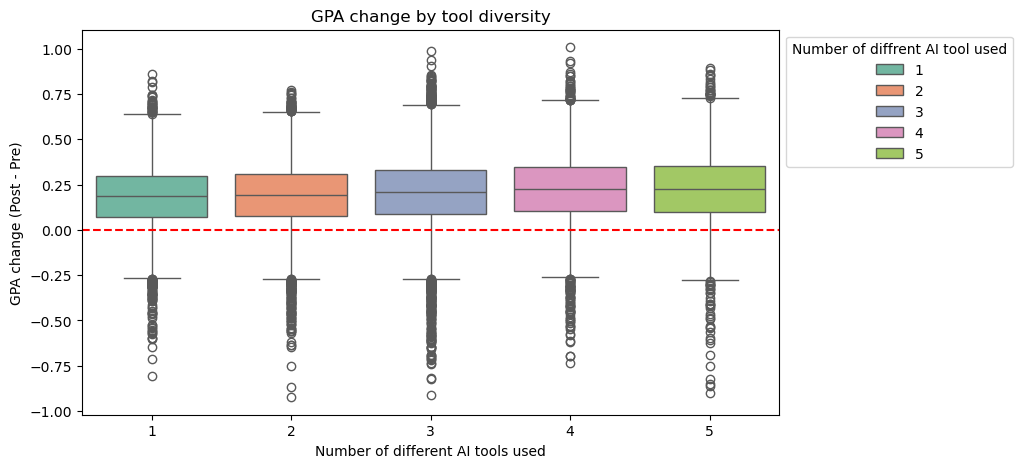

In [33]:
# print(df_p2.groupby("Tool_Diversity")["GPA_Change"].agg(["count", "mean", "median", "std"]).round(3))

plt.figure(figsize=(9, 5))

ax = sns.boxplot(data=df_p2, x="Tool_Diversity", y="GPA_Change", hue="Tool_Diversity", palette="Set2", legend = True)

plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Number of different AI tools used")
plt.ylabel("GPA change (Post - Pre)")
plt.title("GPA change by tool diversity")

ax.legend(title="Number of diffrent AI tool used", bbox_to_anchor=(1.0, 1))

plt.show()

Q4. Look at relationships. Make at least three plots that relate two or more features, chosen with your research questions in mind:a scatter plot, a comparison across subgroups, a time series, or a correlation matrix. If you have a secondary dataset, at least one of these should use the join or comparison you described in the last checkpoint.

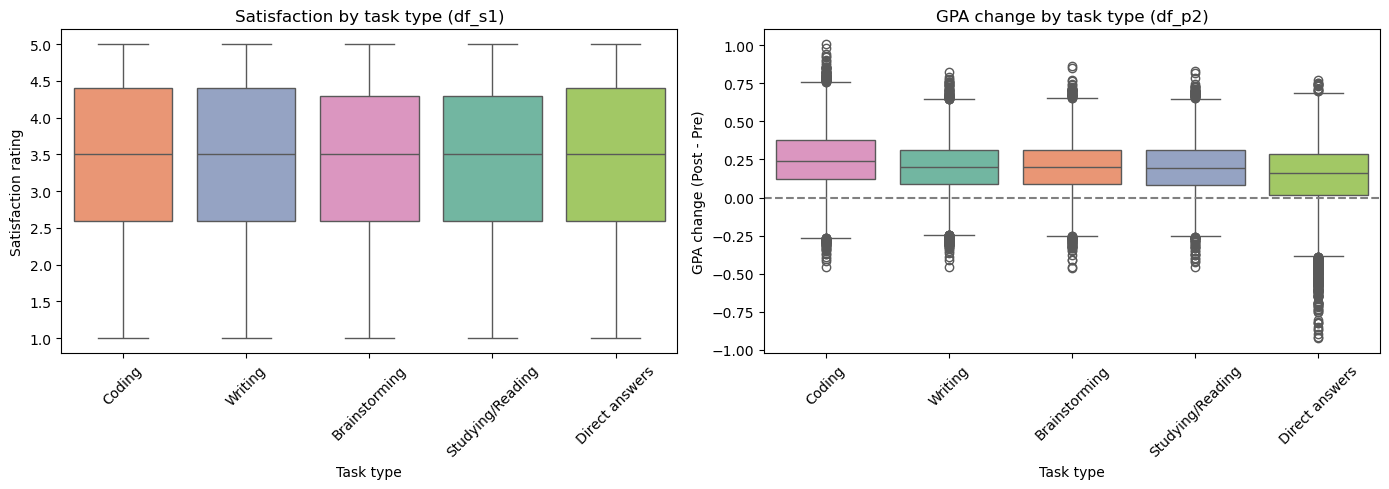

In [36]:
# Box plot shows the median, the middle 50% of values, the overall range, and any outliers for each task type, 
# which lets us compare not only the typical value across tasks but also the spread and skew within each task. 
# Using the same task order on both plots makes the two datasets easy to compare side by side.
# By pairing satisfaction against performance across categories, we might diagnose why students lean into risky use cases: 
# their subjective satisfaction tricks them into a false sense of academic security.

# print(df_s1["TaskType"].value_counts())
# print(df_s1["FinalOutcome"].value_counts())
# print(df_p2["Primary_Use_Case"].value_counts())

s1_map = {
    "Coding": "Coding",
    "Writing": "Writing",
    "Brainstorming": "Brainstorming",
    "Studying": "Studying/Reading",
    "Research": "Studying/Reading",
    "Homework Help": "Direct answers",
}
p2_map = {
    "Debugging/Troubleshooting": "Coding",
    "Copywriting/Drafting": "Writing",
    "Ideation": "Brainstorming",
    "Summarizing_Reading": "Studying/Reading",
    "Direct_Answer_Generation": "Direct answers",
}

df_s1["Task_Common"] = df_s1["TaskType"].map(s1_map)
df_p2["Task_Common"] = df_p2["Primary_Use_Case"].map(p2_map)

# print(df_s1["Task_Common"].value_counts())
# print(df_p2["Task_Common"].value_counts())


order = ["Coding", "Writing", "Brainstorming", "Studying/Reading", "Direct answers"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_s1, x="Task_Common", y="SatisfactionRating", order=order, hue="Task_Common", palette="Set2", ax=axes[0])
axes[0].set_title("Satisfaction by task type (df_s1)")
axes[0].set_xlabel("Task type")
axes[0].set_ylabel("Satisfaction rating")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(data=df_p2, x="Task_Common", y="GPA_Change", order=order, hue="Task_Common", palette="Set2", ax=axes[1])
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set_title("GPA change by task type (df_p2)")
axes[1].set_xlabel("Task type")
axes[1].set_ylabel("GPA change (Post - Pre)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

FinalOutcome      Assignment Completed  Confused  Gave Up  Idea Drafted
Task_Common                                                            
Coding                            59.9      16.2      5.7          18.2
Writing                           48.5      10.7      5.4          35.4
Brainstorming                     28.6      15.8      7.4          48.3
Studying/Reading                  38.7      20.9     10.0          30.4
Direct answers                    50.4      18.5      9.6          21.4


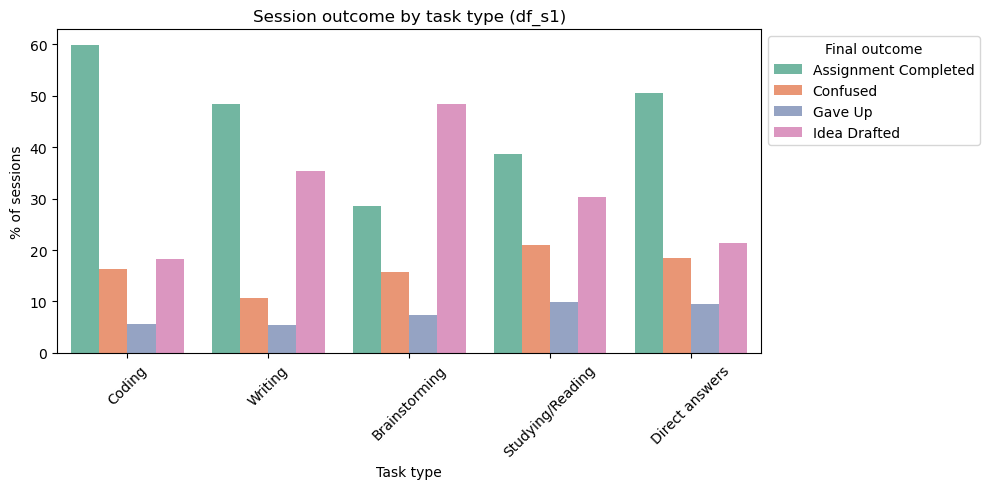

In [47]:
# count sessions per task type and outcome 
outcome_counts = df_s1.pivot_table(index="Task_Common", columns="FinalOutcome", aggfunc="size")

# convert counts to % of each task type (percentage will easier to compare when looking at the visualization )
outcome_pct = outcome_counts.div(outcome_counts.sum(axis=1), axis=0).reindex(order) * 100
print(outcome_pct.round(1))

# reshape to long format for seaborn
outcome_long = outcome_pct.reset_index().melt(id_vars="Task_Common", var_name="FinalOutcome", value_name="Percent")

# grouped bar chart
plt.figure(figsize=(10, 5))
sns.barplot(data=outcome_long, x="Task_Common", y="Percent", hue="FinalOutcome", order=order, palette="Set2")

plt.xlabel("Task type")
plt.ylabel("% of sessions")
plt.title("Session outcome by task type (df_s1)")
plt.xticks(rotation=45)

plt.legend(title="Final outcome", bbox_to_anchor=(1.0, 1))
plt.tight_layout()
plt.show()

count    50000.000000
mean        11.209271
std          5.156426
min          1.000000
25%          7.560000
50%         11.180000
75%         14.710000
max         35.860000
Name: Traditional_Study_Hours, dtype: float64
Missing values: 0


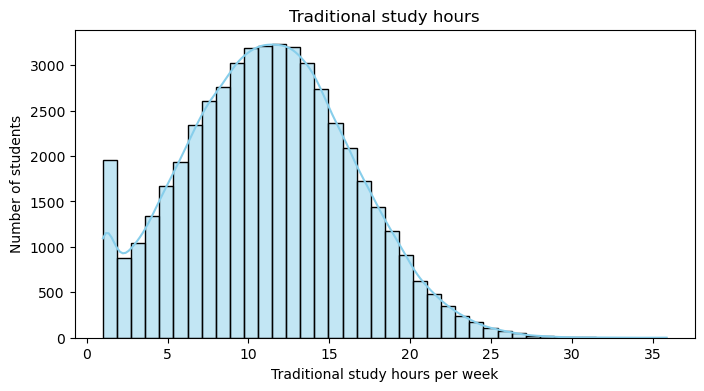

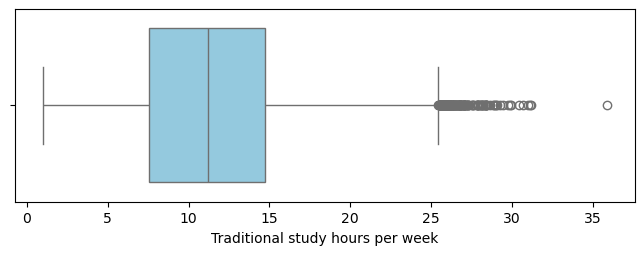

In [48]:
print(df_p2["Traditional_Study_Hours"].describe())
print("Missing values:", df_p2["Traditional_Study_Hours"].isna().sum())

plt.figure(figsize=(8, 4))
sns.histplot(df_p2["Traditional_Study_Hours"], bins=40, kde=True, color="skyblue")
plt.xlabel("Traditional study hours per week")
plt.ylabel("Number of students")
plt.title("Traditional study hours")
plt.show()

plt.figure(figsize=(8, 2.5))
sns.boxplot(x=df_p2["Traditional_Study_Hours"], color="skyblue")
plt.xlabel("Traditional study hours per week")
plt.show()